<a href="https://colab.research.google.com/github/aashishneupanecs24-creator/BIOS-LAB-1BF24CS004/blob/main/Ant_Synchronization_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best path: A -> B -> C -> D -> E -> F
Shortest distance: 8


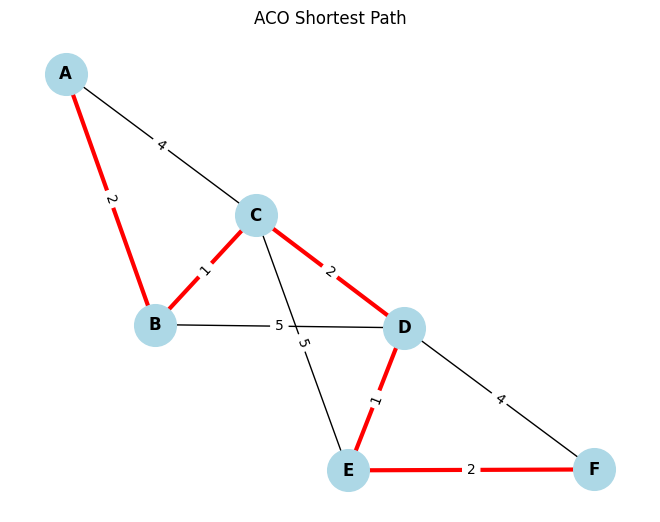

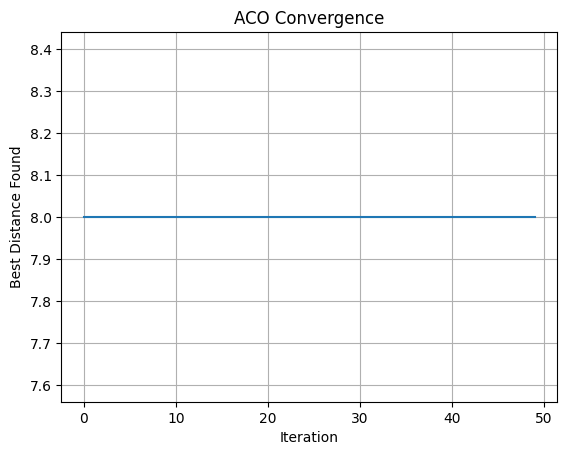

In [1]:

import random
import networkx as nx
import matplotlib.pyplot as plt

random.seed(42)

# Create a weighted graph
G = nx.Graph()

edges = [
    ("A", "B", 2),
    ("A", "C", 4),
    ("B", "C", 1),
    ("B", "D", 5),
    ("C", "D", 2),
    ("C", "E", 5),
    ("D", "E", 1),
    ("D", "F", 4),
    ("E", "F", 2)
]

for u, v, distance in edges:
    G.add_edge(u, v, weight=distance)

start = "A"
end = "F"

# ACO parameters
ants = 10
iterations = 50
alpha = 1.0       # Importance of pheromone
beta = 2.0        # Importance of distance
evaporation = 0.5
Q = 100

# Initialize pheromone on every edge
pheromone = {edge: 1.0 for edge in G.edges()}
pheromone.update({(v, u): 1.0 for u, v in G.edges()})

best_path = None
best_distance = float("inf")
history = []

for iteration in range(iterations):
    all_paths = []

    for ant in range(ants):
        path = [start]
        visited = {start}
        current = start

        # Build a route without revisiting nodes
        while current != end:
            candidates = [
                node for node in G.neighbors(current)
                if node not in visited
            ]

            if not candidates:
                break

            weights = []
            for node in candidates:
                distance = G[current][node]["weight"]
                trail = pheromone[(current, node)]
                weights.append(
                    (trail ** alpha) * ((1 / distance) ** beta)
                )

            total = sum(weights)
            probabilities = [w / total for w in weights]
            next_node = random.choices(
                candidates, weights=probabilities, k=1
            )[0]

            path.append(next_node)
            visited.add(next_node)
            current = next_node

        # Keep only routes that reach the destination
        if current == end:
            distance = sum(
                G[path[i]][path[i + 1]]["weight"]
                for i in range(len(path) - 1)
            )

            all_paths.append((path, distance))

            if distance < best_distance:
                best_path = path.copy()
                best_distance = distance

    # Evaporate pheromone
    for edge in pheromone:
        pheromone[edge] *= (1 - evaporation)

    # Better (shorter) routes deposit more pheromone
    for path, distance in all_paths:
        deposit = Q / distance
        for i in range(len(path) - 1):
            u, v = path[i], path[i + 1]
            pheromone[(u, v)] += deposit
            pheromone[(v, u)] += deposit

    history.append(best_distance)

# Display results
print("Best path:", " -> ".join(best_path))
print("Shortest distance:", best_distance)

# Draw the network and highlight the best route
pos = nx.spring_layout(G, seed=7)
path_edges = list(zip(best_path, best_path[1:]))

nx.draw(
    G, pos, with_labels=True, node_color="lightblue",
    node_size=900, font_weight="bold"
)

nx.draw_networkx_edges(
    G, pos, edgelist=path_edges,
    edge_color="red", width=3
)

edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title("ACO Shortest Path")
plt.show()

# Plot convergence
plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Best Distance Found")
plt.title("ACO Convergence")
plt.grid(True)
plt.show()
